# Risk of bias (QUIPS)

In [ ]:
suppressPackageStartupMessages({
  library(tidyverse); library(gt); library(scales); library(patchwork)
})


Pool: 100 studies (inclusive_pool=FALSE, drop_contaminated=TRUE)

# QUIPS framework

Risk of bias was assessed with the QUIPS tool (Hayden et al. 2013), scoring six domains 1 (low), 2 (moderate), 3 (high):

1.  **Study participation** (selection bias)
2.  **Study confounding** (multivariable adjustment for key confounders)
3.  **Outcome measurement** (ascertainment / objectivity)
4.  **Statistical analysis** (appropriateness, reporting completeness)
5.  **Attrition** (loss to follow-up, missing data)
6.  **Prognostic factor measurement** (TTP measurement quality)

Overall rating follows QUIPS guidance — worst-domain-dominates, not arithmetic mean. See `references/QUIPS_scoring_guide.md` in the extraction skill for the project-specific rubric.

# Domain-level scores

In [ ]:
rob_long <- tbl_study |>
  select(study_id, pub_year,
         starts_with("rob_")) |>
  pivot_longer(starts_with("rob_") & !ends_with("overall"),
               names_to = "domain", values_to = "score") |>
  mutate(
    domain = recode(domain,
      rob_selection = "Selection",
      rob_comparability = "Comparability",
      rob_outcome = "Outcome",
      rob_stat_analysis = "Stat. analysis",
      rob_attrition = "Attrition",
      rob_prognostic_measurement = "Prognostic measurement"
    ),
    score_lbl = factor(case_when(
      score == 1 ~ "Low",
      score == 2 ~ "Moderate",
      score == 3 ~ "High",
      TRUE ~ "NR"
    ), levels = c("Low", "Moderate", "High", "NR"))
  )


## Traffic-light plot

Warning in set2(resolve(...)): The object is read-only and cannot be modified.
If you have to modify it for a legitimate reason, call the method $lock(FALSE)
on the object before $set(). Using $lock(FALSE) to modify the object will be
enforced in future versions of knitr and this warning will become an error.

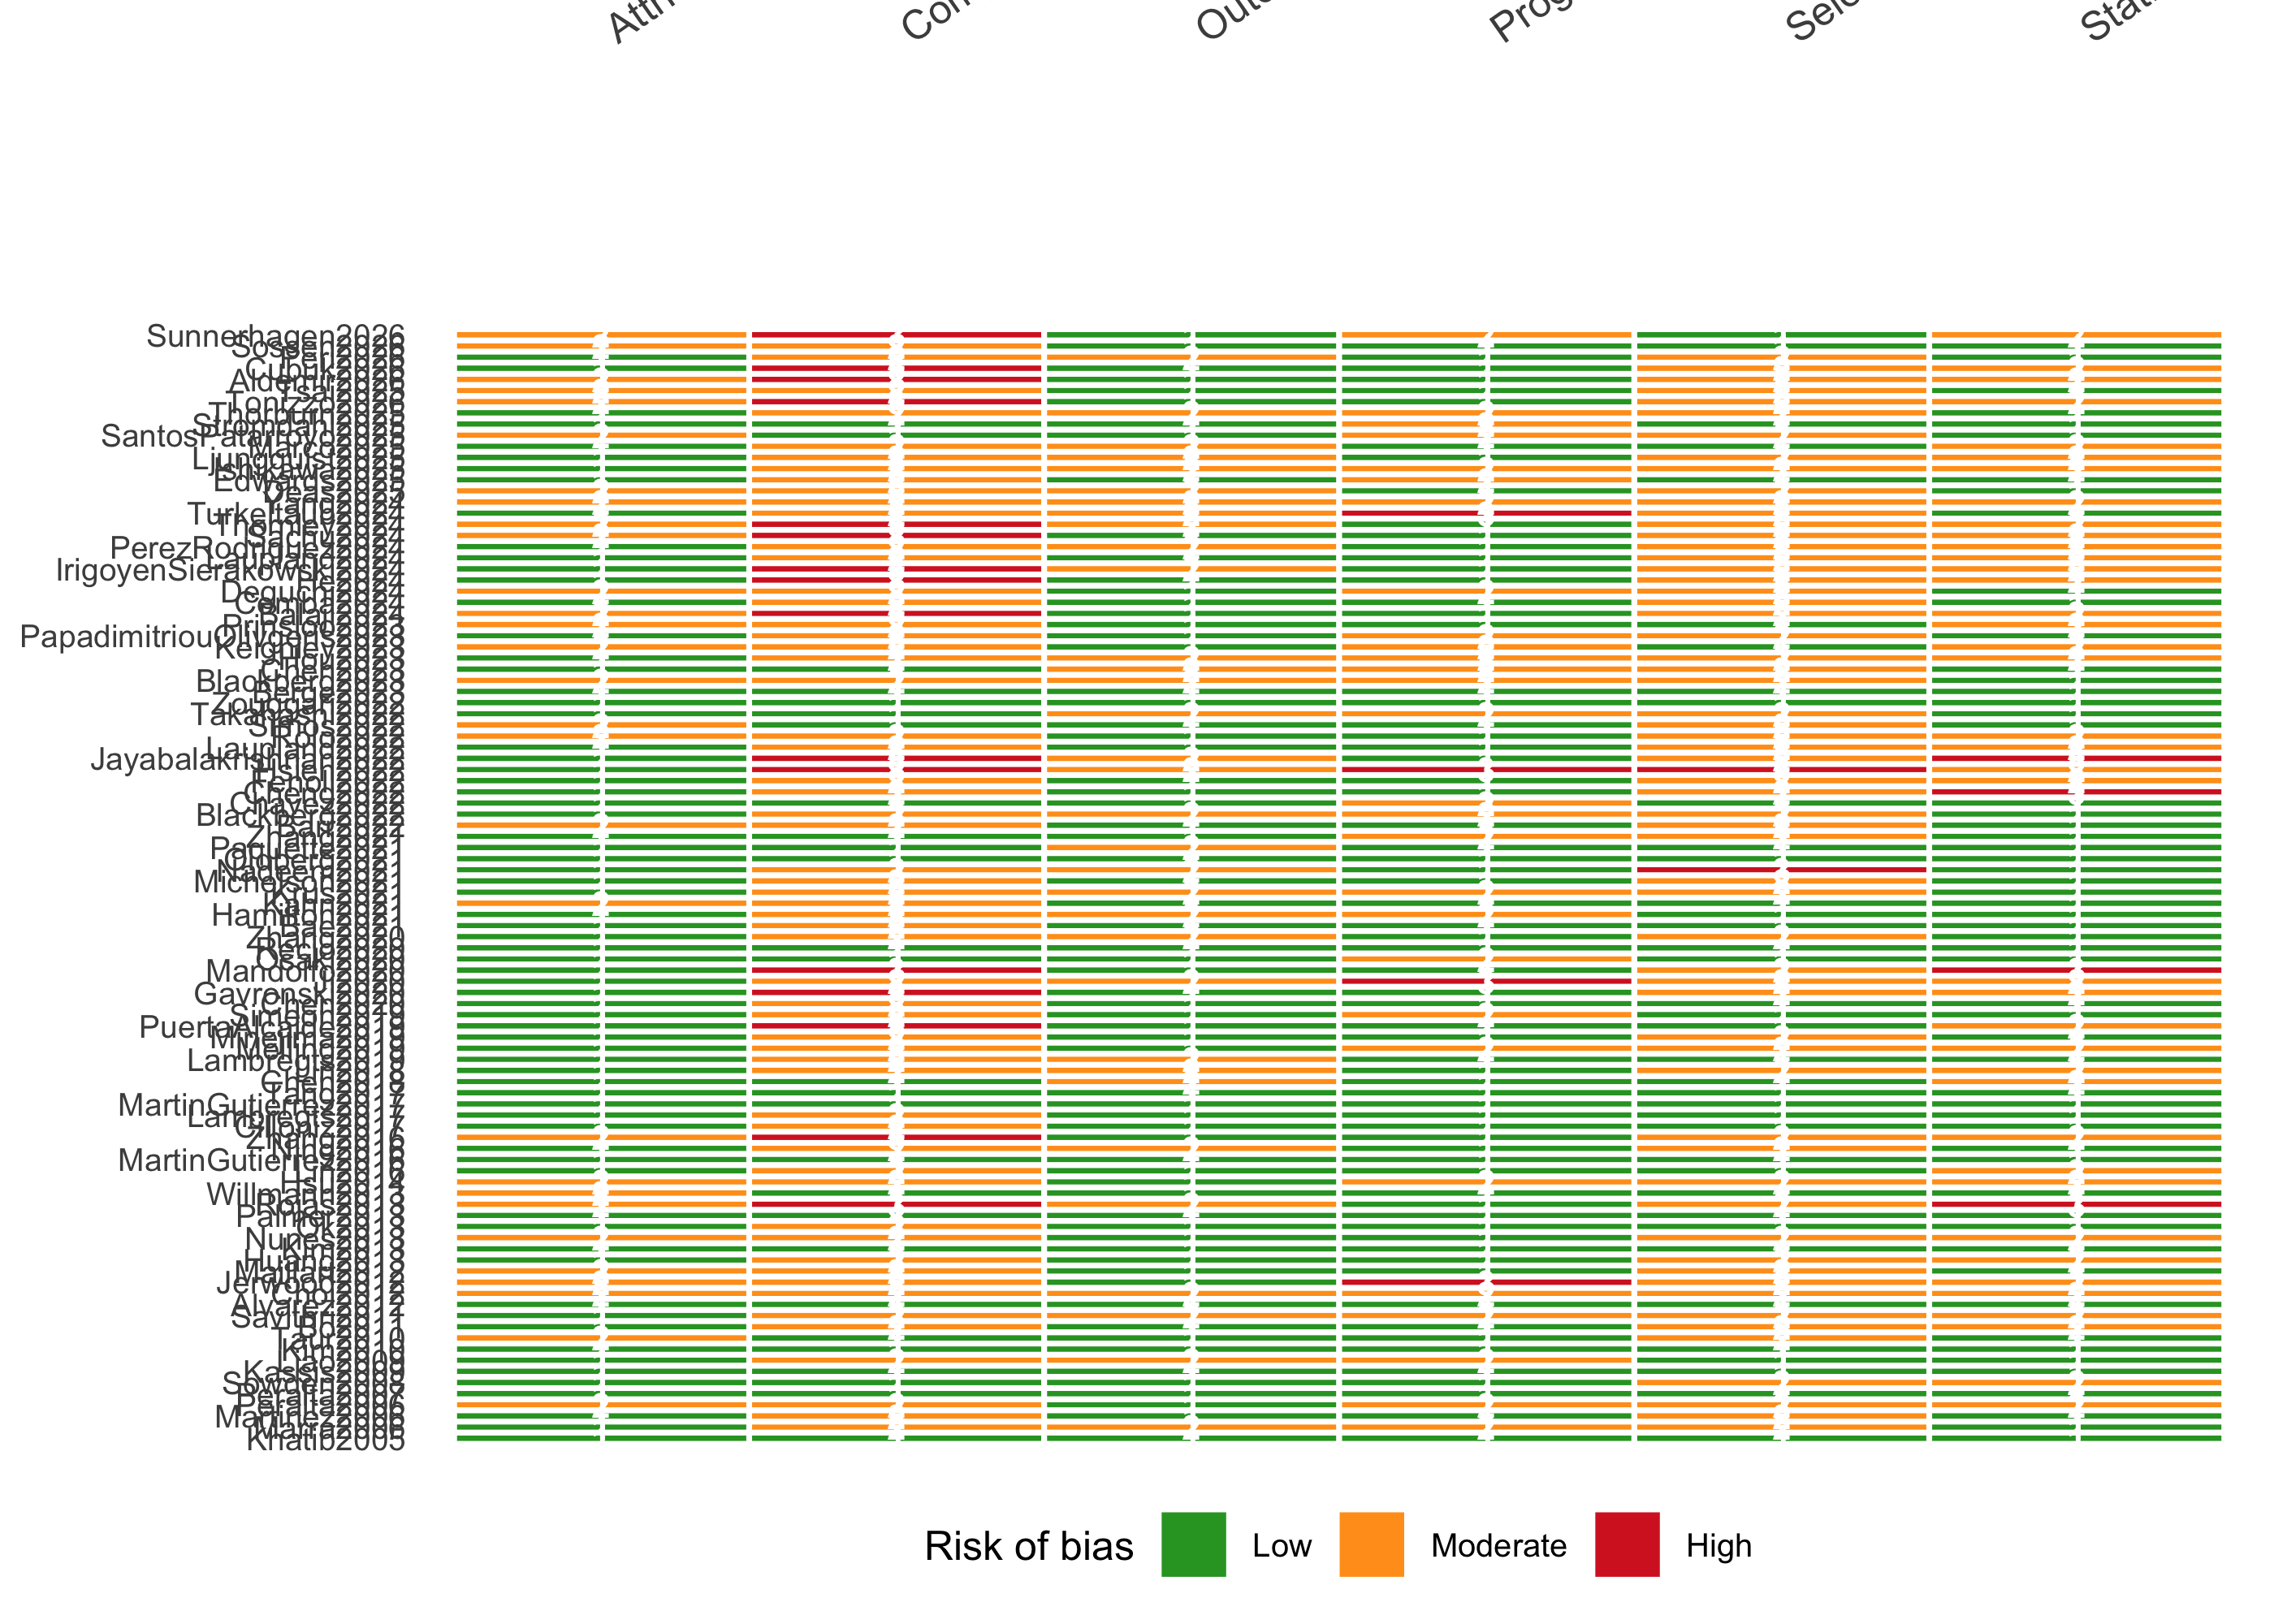

In [ ]:

knitr::opts_current$set(fig.height = max(8, nrow(tbl_study) * 0.15 + 2))


## Summary plot (domain-by-rating)

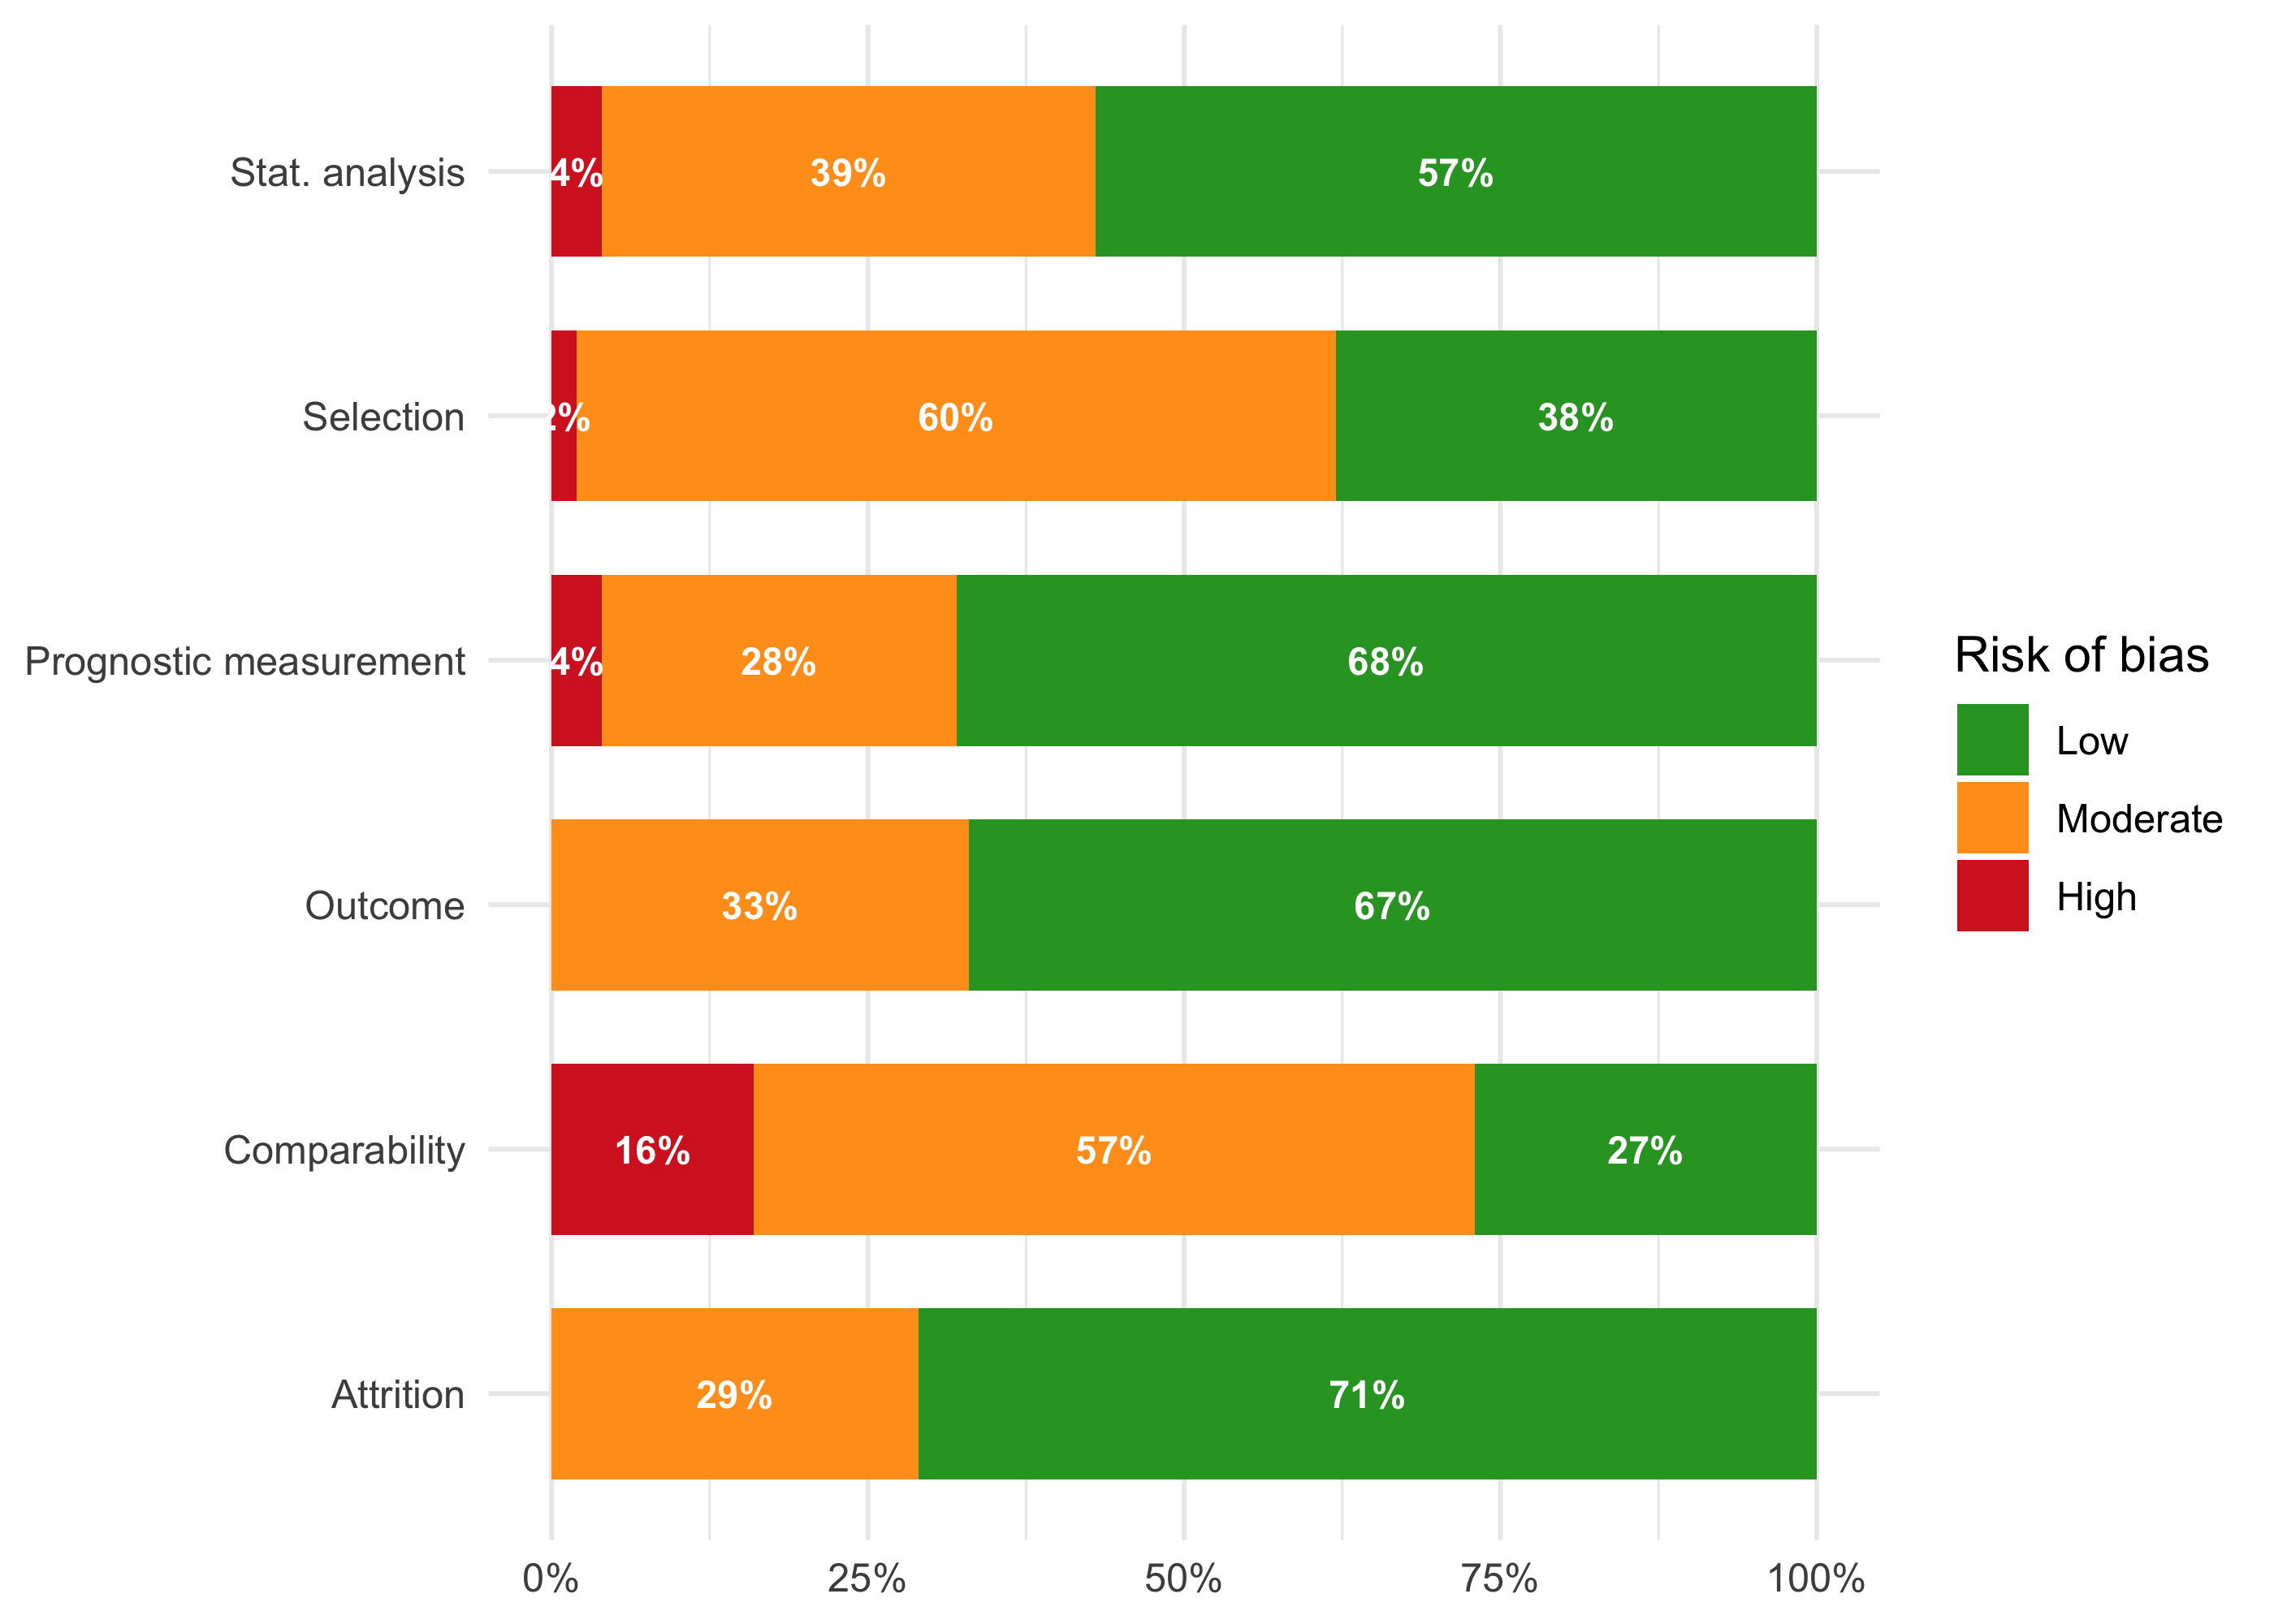

In [ ]:
rob_long |>
  count(domain, score_lbl) |>
  group_by(domain) |>
  mutate(pct = n / sum(n)) |>
  ggplot(aes(y = domain, x = pct, fill = score_lbl)) +
  geom_col(width = 0.7) +
  geom_text(aes(label = scales::percent(pct, accuracy = 1)),
            position = position_stack(vjust = 0.5),
            color = "white", size = 3, fontface = "bold") +
  scale_x_continuous(labels = scales::percent_format(accuracy = 1)) +
  scale_fill_manual(values = c("Low" = "#2ca02c", "Moderate" = "#ff9f1c",
                                "High" = "#d62728", "NR" = "gray70"),
                    name = "Risk of bias") +
  labs(x = NULL, y = NULL) +
  theme_minimal()


# Overall RoB by study

In [ ]:
tbl_study |>
  count(rob_overall) |>
  mutate(`%` = scales::percent(n / sum(n), 1)) |>
  arrange(factor(rob_overall, levels = c("low", "moderate", "high", "critical"))) |>
  gt() |>
  cols_label(rob_overall = "Overall rating", n = "Studies")


# Effect-size weighted RoB

Studies with higher overall RoB carry more potential to distort the pooled effect. The chart below weights each contribution by inverse-variance:

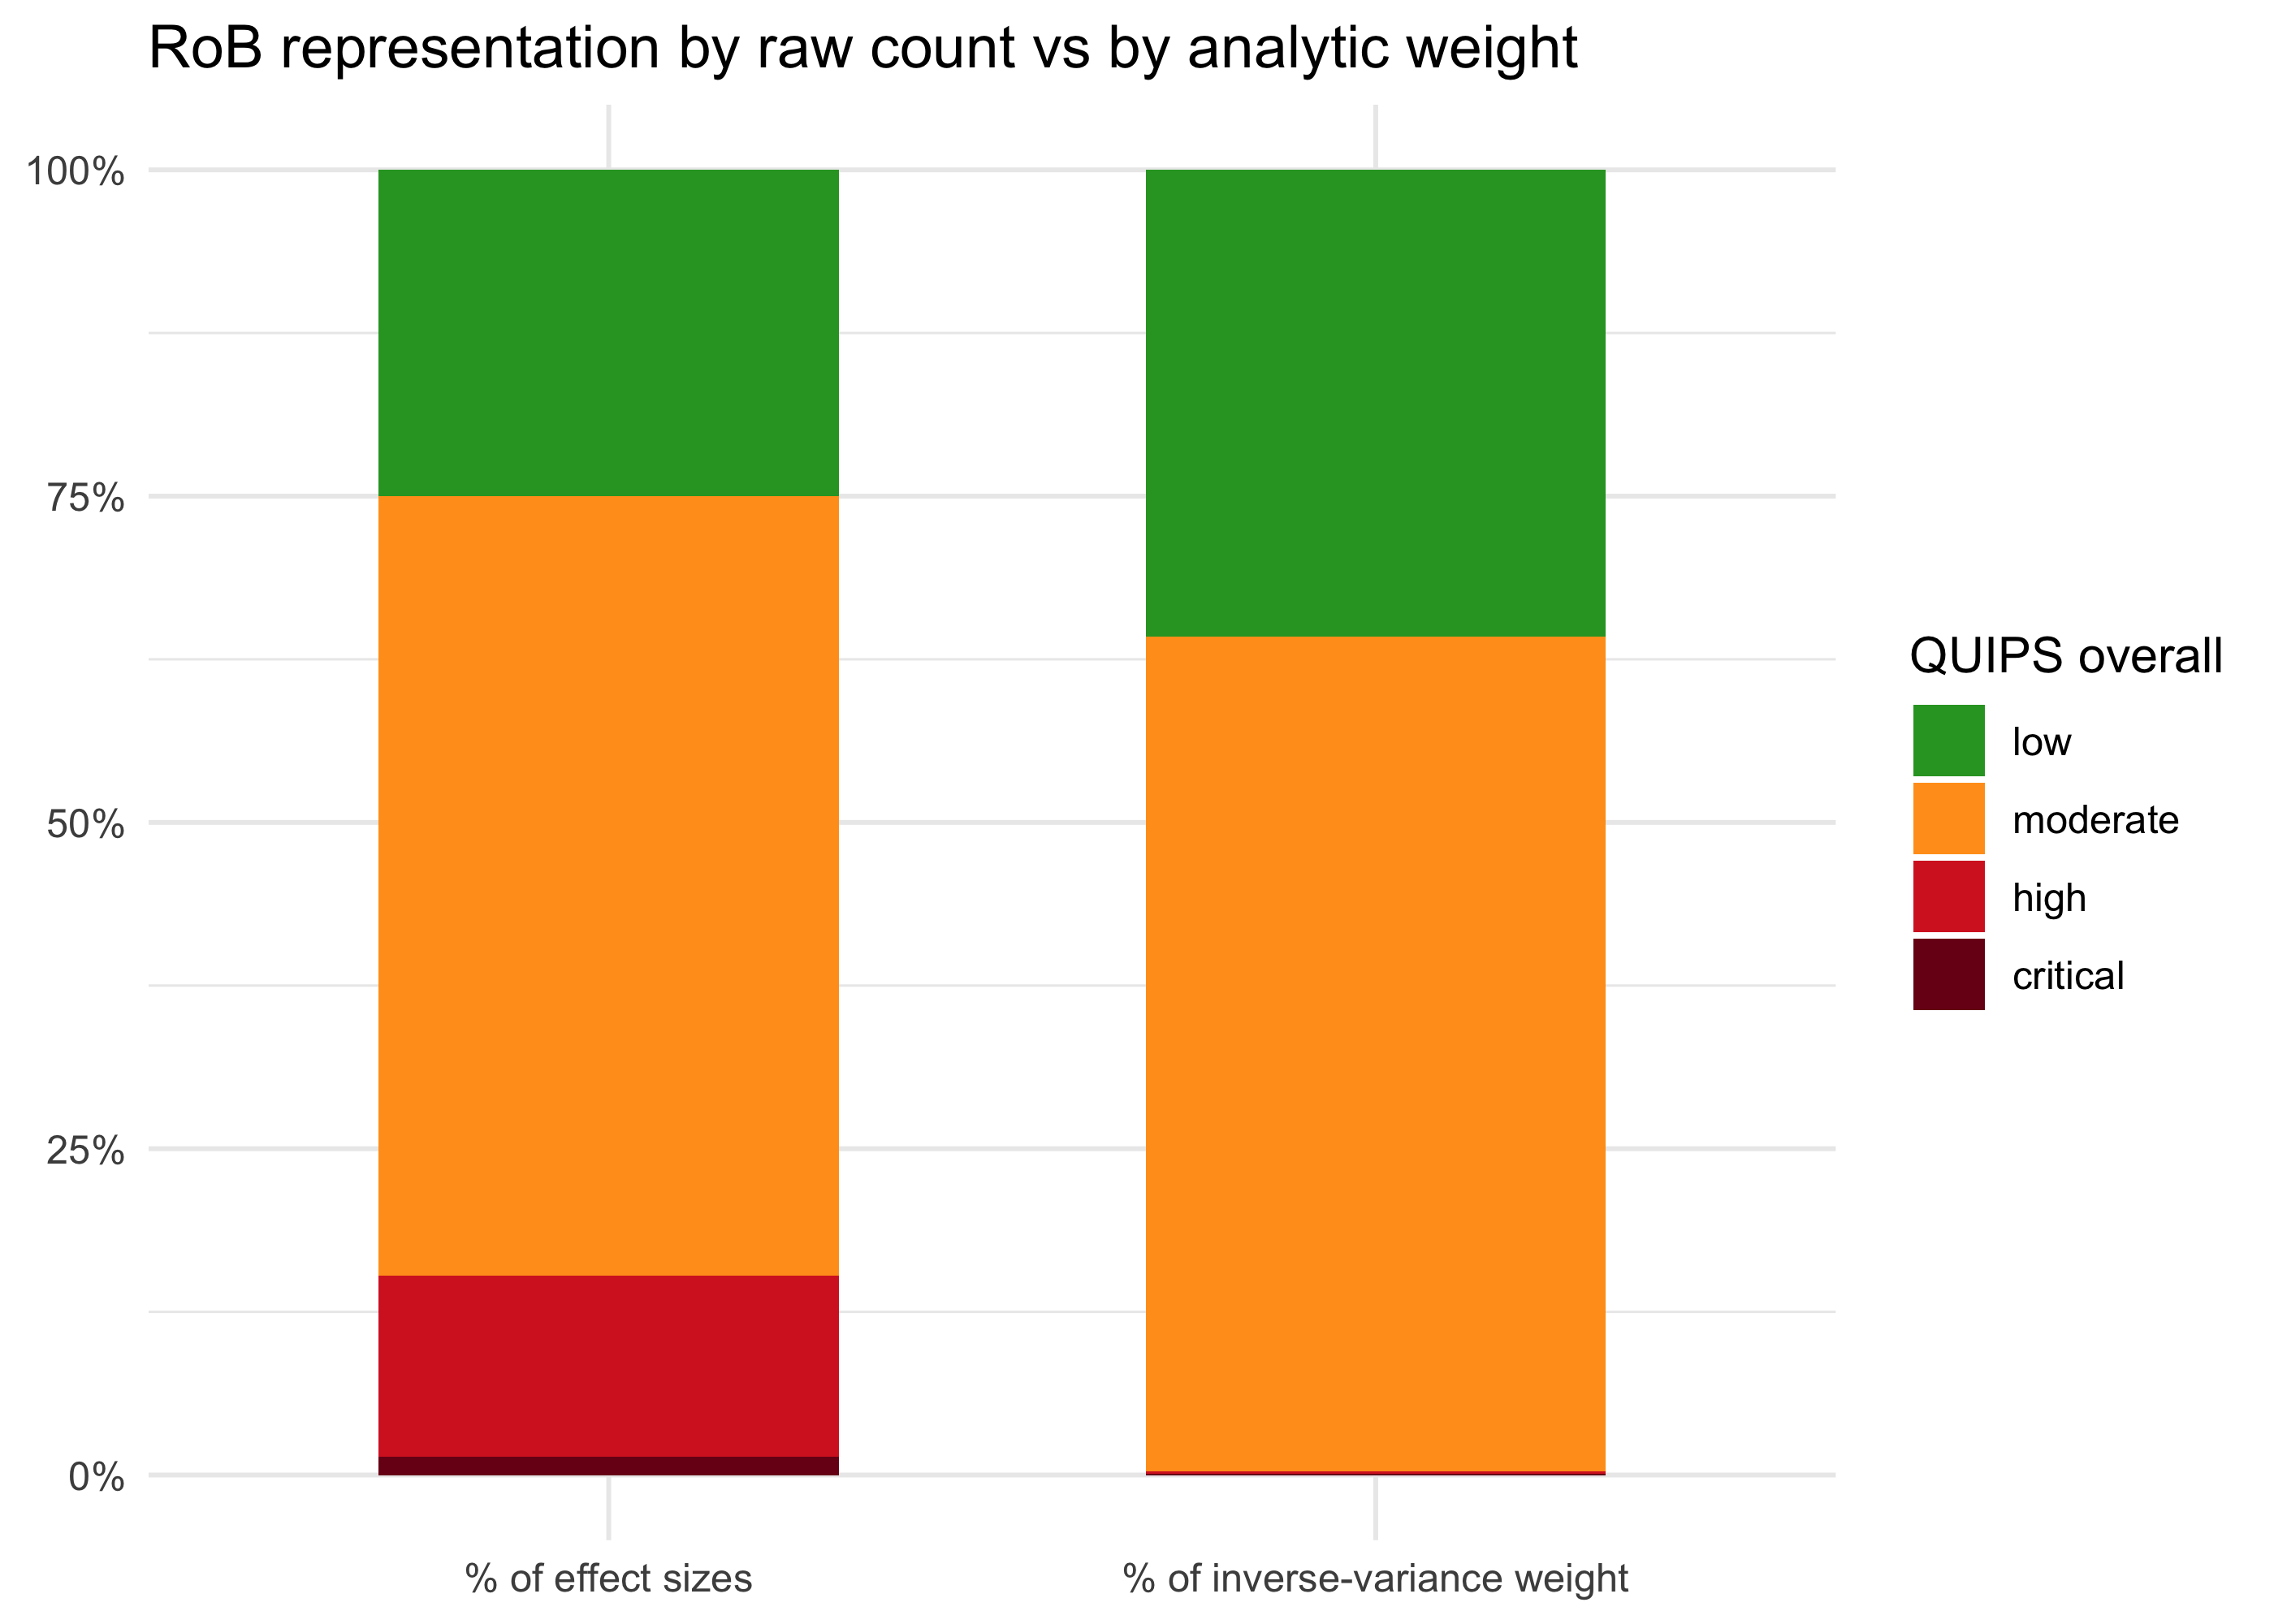

In [ ]:
es_with_rob <- es_all |>
  filter(outcome_type == "mortality")

es_with_rob |>
  mutate(w = 1/vi) |>
  group_by(rob_overall) |>
  summarise(weight = sum(w, na.rm = TRUE), n = n(), .groups = "drop") |>
  mutate(pct_weight = weight / sum(weight),
         pct_n      = n / sum(n)) |>
  pivot_longer(c(pct_weight, pct_n), names_to = "metric", values_to = "pct") |>
  mutate(metric = recode(metric,
                         pct_n = "% of effect sizes",
                         pct_weight = "% of inverse-variance weight")) |>
  ggplot(aes(x = metric, y = pct,
             fill = factor(rob_overall, levels = c("low", "moderate", "high", "critical")))) +
  geom_col(width = 0.6) +
  scale_y_continuous(labels = scales::percent_format(1)) +
  scale_fill_manual(values = c("low" = "#2ca02c", "moderate" = "#ff9f1c",
                                "high" = "#d62728", "critical" = "#7a0019"),
                    name = "QUIPS overall") +
  labs(x = NULL, y = NULL,
       title = "RoB representation by raw count vs by analytic weight") +
  theme_minimal()
